# Stage 4 (part 2) — MLP, regression variants, complete comparison

| Part | Prompt | Code |
|---|---|---|
| 1 | 4.4 Multilayer perceptron | `src/mlp.py` (PyTorch), `models.mlp` |
| 2 | 4.5 Regression variants (log target ± smearing, hurdle, Tweedie) | `src/reg_variants.py`, `models.tweedie` |
| 3 | 4.6 Master tables, red-flag checklist, skeptical review | `src/reporting.py` |

Same runner, folds, slice-based threshold/early stopping, metrics and references as part 1 (rule 7). Approved for this part
(Decisions 4.10–4.12): paired fold-wise comparisons vs seasonal + persistence and vs the best linear model; regression variants
restricted to the boosters plus Ridge/Lasso; all 10 classical models kept in the master tables. The test set is not touched.

### Step 1 — Setup

**WHAT:** imports, paths, seeds, versions (PyTorch is new).

**WHY:** reproducibility; PyTorch's behaviour (e.g. default initialisation) can change between versions.

**Look for:** the PyTorch version and that it runs on CPU.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, models as Mo, splits as S, reg_variants as R, reporting as Rep
from mlp import TorchMLP

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0); torch.manual_seed(0)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 40, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
X, Y = E.load("B")
FOLDS = S.cv_folds(X.index)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| threads:", torch.get_num_threads())

torch 2.14.1+cu130 | CUDA available: False | threads: 4


**Interpretation:** PyTorch 2.14.1 runs on the CPU (4 threads; the installed wheel is the CUDA build from PyPI, but no GPU is used —
results do not depend on it).

**Decision:** version pinned in `requirements.txt`.

**Paper note:** *The multilayer perceptron was implemented in PyTorch 2.14.1 and trained on CPU.*

# Part 1 — Prompt 4.4: Multilayer perceptron

### Step 2 — Design, and why neural networks need scaling and are seed-sensitive

**Architecture:** input (125 columns after one-hot month) → 64 ReLU → dropout 0.1 → 64 ReLU → dropout 0.1 → 1 output.
Optimiser **AdamW** (learning rate 1e-3, **weight decay 1e-4**), mini-batches of 256, at most 150 epochs.
- **Classification:** sigmoid output, binary cross-entropy with `pos_weight = n_dry / n_wet` (class weighting, "balanced").
- **Regression:** three losses compared — **Huber** (quadratic for small errors, linear for large ones; δ = 1 training std
  ≈ 15 mm), **MAE** (L1; estimates the conditional *median*) and **MSE** (estimates the conditional *mean*). Targets are divided
  by their training std.
- **Early stopping:** the same slice as the boosters (last 3 years of the training fold): the epoch with the lowest slice loss
  is kept, patience 15; the final model is then refitted on the whole training fold for exactly that number of epochs.

**Why PyTorch, not `sklearn.neural_network` (rule 13):** scikit-learn's MLP (1.9.1) has no class weights, only squared loss
for regression, and its early stopping uses a *random* validation fraction — which would put future days in the validation set
and past days in training.

**Why scaling matters for neural networks.** Each first-layer neuron computes w·x + b. If pressure (≈ 100 kPa, std 0.5) and rain
(0–5 on log scale) enter unscaled, the same learning rate is far too large for some weights and far too small for others, and
ReLU units saturate; gradient descent zig-zags or stalls. Weight decay also penalises all weights equally, which is only fair if
inputs are on the same scale. Trees do not care (part 1), linear models with penalties do, neural networks need it most.
The scaler is fitted inside `TorchMLP.fit` on the training rows only (rule 6).

**Why NNs are seed-sensitive.** The seed sets the random initial weights, the dropout masks and the mini-batch order. The loss
surface is non-convex, so different seeds end in different local solutions; early stopping then stops each run at a different
epoch. Rule 8 (5 seeds, mean ± std) exists for exactly this.

**Look for (next step):** training loss falling steadily while slice loss flattens and then rises = over-fitting.

### Step 3 — Training and validation curves (fold 5, inner split)

**WHAT:** fit on fold 5's inner-train (targets 1981–2013) and track the loss on the slice (2014–2016) after every epoch:
(a) classification and (b) regression (Huber), default settings, 5 seeds; (c) a deliberately over-fitting network
(256 × 256 units, no dropout, no weight decay, learning rate 3e-3, no early stopping) for comparison.

**WHY:** curves show *how* a network learns and when it starts memorising: the gap between training and validation loss is
over-fitting made visible.

**Alternatives considered:** curves on the fold-5 validation block — would mean looking at validation labels to understand
training; the slice is the honest choice and is what early stopping actually uses.

**Look for:** where the validation curve bottoms out (the early-stopping epoch), the spread across seeds, and the widening gap
in the over-fitting network.

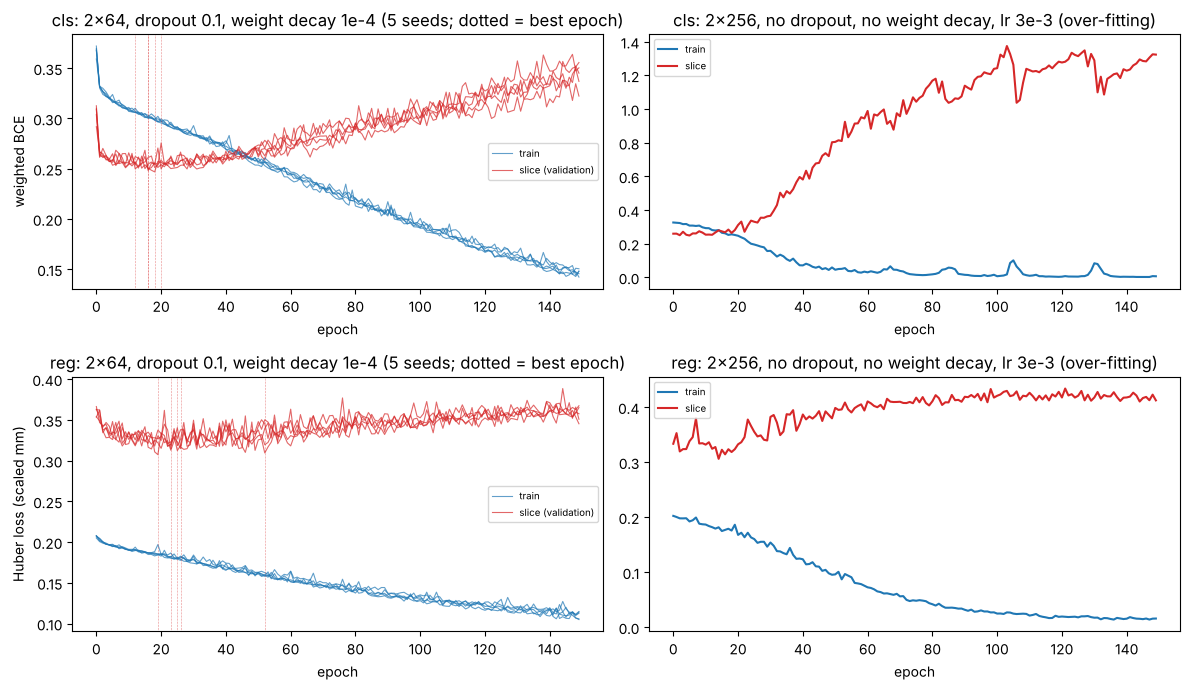

,best epoch,min slice loss
cls seed 0,17.0,0.248
cls seed 1,17.0,0.250
cls seed 2,19.0,0.247
cls seed 3,13.0,0.250
cls seed 4,21.0,0.250
reg seed 0,20.0,0.307
reg seed 1,24.0,0.315
reg seed 2,26.0,0.312
reg seed 3,53.0,0.309
reg seed 4,27.0,0.315


In [2]:
tr5 = FOLDS[4][0]
itr, sl = E.inner_split(tr5)
curves = {}
for task, loss in (("cls", "bce"), ("reg", "huber")):
    y = Y[E.TARGET[task]]
    for seed in Mo.SEEDS:
        m = TorchMLP(task=task, loss=loss, seed=seed, patience=None).fit(X.loc[itr], y[itr], eval_set=(X.loc[sl], y[sl]))
        curves[task, "default", seed] = m.history_
    over = TorchMLP(task=task, loss=loss, seed=0, hidden=(256, 256), dropout=0.0, weight_decay=0.0, lr=3e-3, patience=None)
    curves[task, "overfit", 0] = over.fit(X.loc[itr], y[itr], eval_set=(X.loc[sl], y[sl])).history_

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r, (task, ylab) in enumerate((("cls", "weighted BCE"), ("reg", "Huber loss (scaled mm)"))):
    for seed in Mo.SEEDS:
        h = curves[task, "default", seed]
        axes[r, 0].plot(h["train"], color="tab:blue", lw=0.8, alpha=0.7, label="train" if seed == 0 else None)
        axes[r, 0].plot(h["val"], color="tab:red", lw=0.8, alpha=0.7, label="slice (validation)" if seed == 0 else None)
        axes[r, 0].axvline(int(np.argmin(h["val"])), color="tab:red", lw=0.4, ls=":")
    h = curves[task, "overfit", 0]
    axes[r, 1].plot(h["train"], color="tab:blue", label="train"); axes[r, 1].plot(h["val"], color="tab:red", label="slice")
    axes[r, 0].set(title=f"{task}: 2x64, dropout 0.1, weight decay 1e-4 (5 seeds; dotted = best epoch)", ylabel=ylab)
    axes[r, 1].set(title=f"{task}: 2x256, no dropout, no weight decay, lr 3e-3 (over-fitting)")
    for a in axes[r]: a.set_xlabel("epoch"); a.legend(fontsize=7)
fig.tight_layout(); save(fig, "04_mlp_learning_curves.png"); plt.show()
best = pd.DataFrame({f"{t} seed {s}": {"best epoch": int(np.argmin(curves[t, 'default', s]['val'])) + 1,
                                       "min slice loss": min(curves[t, 'default', s]['val'])}
                     for t in ("cls", "reg") for s in Mo.SEEDS}).T
best.round(4)

**Interpretation:**
- **Classification (default network):** the slice loss reaches its minimum after **13–21 epochs** (BCE ≈ 0.248 for all seeds) and
  then rises steadily to ≈ 0.35 at epoch 150, while the training loss keeps falling from 0.33 to 0.15. The point where the two curves
  diverge is where the network starts memorising training years instead of learning rules that transfer to new years.
- **Regression (Huber):** best epochs 20–53; the slice loss is noisier and rises slowly — less signal to learn, so over-fitting
  shows up more as noise.
- **Over-fitting network** (2×256, no dropout, no weight decay, higher learning rate): training loss → 0 (perfect memorisation),
  slice loss explodes from 0.26 to ≈ 1.3 for classification. This is what over-fitting looks like: a widening gap, and validation
  loss that gets *worse* the longer you train.
- **Seeds:** the five default curves have the same shape but different minima and best epochs (13–21 / 20–53) — the seed
  sensitivity rule 8 guards against.

**Decision:** early stopping is essential for this model; the default regularisation (dropout 0.1, weight decay 1e-4) is kept.

**Paper note:** *Learning curves showed the onset of over-fitting after 13–21 epochs for classification; early stopping on a
chronologically held-out slice was therefore used to fix the number of training epochs.*

### Step 4 — Cross-validate the MLP (Sets A and B, 5 seeds)

**WHAT:** `mlp` for classification; `mlp_huber`, `mlp_mae`, `mlp_mse` for regression; each on Sets A and B with seeds 0–4,
through the shared runner (inner fit with early stopping on the slice → refit for the chosen number of epochs).

**WHY:** identical protocol to every other model; three regression losses answer "does the loss function matter?".

**Look for:** run times, and BSS / MAE per seed (seed sensitivity).

In [3]:
def run(name, factory, task, fsets=("A", "B"), seeds=Mo.SEEDS):
    for fset in fsets:
        for seed in seeds:
            t0 = time.time()
            r, _, _ = E.run_cv(name, factory, task, fset, seed)
            m = "BSS" if task == "cls" else "MAE"
            print(f"{task} {fset} {name:12s} seed {seed}: {m} {r[r.metric == m]['value'].mean():.3f} "
                  f"(epochs {r[r.metric == 'n_trees']['value'].mean():.0f}, {time.time() - t0:.0f}s)")

run("mlp", Mo.mlp("cls"), "cls")
for loss in ("huber", "mae", "mse"):
    run(f"mlp_{loss}", Mo.mlp("reg", loss), "reg")

cls A mlp          seed 0: BSS 0.235 (epochs 15, 13s)


cls A mlp          seed 1: BSS 0.245 (epochs 18, 16s)


cls A mlp          seed 2: BSS 0.243 (epochs 15, 14s)


cls A mlp          seed 3: BSS 0.242 (epochs 16, 15s)


cls A mlp          seed 4: BSS 0.248 (epochs 16, 13s)


...

reg B mlp_mse      seed 0: MAE 6.980 (epochs 19, 16s)


reg B mlp_mse      seed 1: MAE 7.183 (epochs 14, 14s)


reg B mlp_mse      seed 2: MAE 7.121 (epochs 17, 14s)


reg B mlp_mse      seed 3: MAE 7.053 (epochs 13, 13s)


reg B mlp_mse      seed 4: MAE 7.116 (epochs 13, 13s)


**Interpretation:** each MLP run takes 13–24 s; early stopping chooses 13–31 epochs. Classification BSS ranges 0.235–0.248 across
seeds; regression MAE varies by up to 0.24 mm between seeds (mlp_mae Set A: 6.75–6.99) — clearly more seed-dependent than the trees.

**Decision:** report the 5-seed mean ± seed std (Step 5, Step 15).

**Paper note:** *MLP performance varied more across random seeds than that of tree ensembles (up to 0.24 mm day⁻¹ in MAE).*

### Step 5 — MLP vs the part-1 models

**WHAT:** the master-table helper (`reporting.master_table`) for the MLPs, the best linear model, the boosters and the
references: mean ± fold std, folds 1–3 vs 4–5, seed std, and **paired win counts** vs seasonal + persistence and vs the best
linear model of the same feature set (`logreg_l1` / `lasso`).

**WHY:** approved decision 4.11 — paired wins are the honest comparison because period difficulty dominates the fold std.

**Look for:** whether the MLP beats the reference in 5/5 folds, its seed std compared with the trees, and which regression
loss works best for MAE.

In [4]:
cv = pd.read_csv(E.RESULTS)
SP, CLS_LIN, REG_LIN = ("baseline:seasonal+persistence", "-"), ("logreg_l1", None), ("lasso", None)
CLS_KEY = ["PR_AUC", "BSS", "BSS_vs_seas_pers", "ROC_AUC", "ROC_AUC_monsoon", "CSI", "ECE"]
REG_KEY = ["MAE", "MSESS", "MSESS_vs_seas_pers", "RMSE", "bias", "spearman_rho", "MAE_wet", "recall_ge20", "recall_ge50"]
sel = ["mlp", "logreg_l1", "catboost", "lightgbm", "xgboost", "baseline:seasonal+persistence"]
display(Rep.master_table(cv[cv.model.isin(sel)], "cls", CLS_KEY, ("BSS", "PR_AUC"),
                         {"seas+pers": SP, "logreg_l1": CLS_LIN}))
sel = ["mlp_huber", "mlp_mae", "mlp_mse", "lasso", "catboost", "lightgbm", "xgboost", "baseline:seasonal+persistence"]
Rep.master_table(cv[cv.model.isin(sel)], "reg", REG_KEY, ("MAE", "MSESS"), {"seas+pers": SP, "lasso": REG_LIN})

metric                                            PR_AUC            BSS BSS_vs_seas_pers        ROC_AUC ROC_AUC_monsoon            CSI            ECE  BSS folds 1-3  BSS folds 4-5  BSS seed std  n_seeds  \
model                         feature_set                                                                                                                                                                    
catboost                      B            0.952 ± 0.019  0.261 ± 0.062    0.095 ± 0.027  0.955 ± 0.011   0.792 ± 0.041  0.822 ± 0.031  0.029 ± 0.006          0.223          0.318         0.003        5   
xgboost                       A            0.953 ± 0.018  0.261 ± 0.070    0.095 ± 0.035  0.955 ± 0.012   0.797 ± 0.036  0.820 ± 0.029  0.027 ± 0.006          0.217          0.326         0.002        5   
catboost                      A            0.952 ± 0.018  0.259 ± 0.066    0.094 ± 0.032  0.955 ± 0.012   0.796 ± 0.039  0.819 ± 0.031  0.028 ± 0.006          0.218          0.321         0.002        5   
lightgbm                      B            0.952 ± 0.019  0.259 ± 0.063    0.093 ± 0.033  0.955 ± 0.012   0.798 ± 0.040  0.819 ± 0.030  0.028 ± 0.004          0.219          0.319         0.001        5   
xgboost                       B            0.953 ± 0.019  0.259 ± 0.062    0.092 ± 0.030  0.955 ± 0.012   0.797 ± 0.040  0.820 ± 0.030  0.028 ± 0.005          0.219          0.317         0.002        5   
lightgbm                      A            0.953 ± 0.019  0.258 ± 0.073    0.093 ± 0.040  0.955 ± 0.012   0.799 ± 0.038  0.816 ± 0.031  0.027 ± 0.006          0.212          0.328         0.001        5   
logreg_l1                     B            0.954 ± 0.015  0.253 ± 0.051    0.084 ± 0.009  0.955 ± 0.009   0.799 ± 0.031  0.817 ± 0.017  0.030 ± 0.006          0.226          0.293         0.000        5   
                              A            0.954 ± 0.016  0.247 ± 0.054    0.077 ± 0.012  0.954 ± 0.010   0.802 ± 0.035  0.821 ± 0.029  0.033 ± 0.008          0.217          0.292         0.000        5   
mlp                           B            0.952 ± 0.017  0.243 ± 0.057    0.073 ± 0.025  0.954 ± 0.010   0.788 ± 0.035  0.816 ± 0.029  0.028 ± 0.006          0.211          0.290         0.003        5   
                              A            0.952 ± 0.017  0.243 ± 0.060    0.073 ± 0.023  0.953 ± 0.011   0.790 ± 0.036  0.817 ± 0.028  0.030 ± 0.004          0.206          0.297         0.005        5   
baseline:seasonal+persistence -            0.932 ± 0.028  0.184 ± 0.058    0.000 ± 0.000  0.945 ± 0.014   0.734 ± 0.042  0.813 ± 0.032  0.043 ± 0.017          0.156          0.225         0.000        1   

metric                                    wins vs seas+pers wins vs logreg_l1  
model                         feature_set                                      
catboost                      B                         5/5               4/5  
xgboost                       A                         5/5               3/5  
catboost                      A                         5/5               4/5  
lightgbm                      B                         5/5               4/5  
xgboost                       B                         5/5               3/5  
lightgbm                      A                         5/5               3/5  
logreg_l1                     B                         5/5               0/5  
                              A                         5/5               0/5  
mlp                           B                         5/5               1/5  
                              A                         5/5               2/5  
baseline:seasonal+persistence -                         0/5               NaN

metric                                               MAE          MSESS MSESS_vs_seas_pers            RMSE            bias   spearman_rho         MAE_wet    recall_ge20    recall_ge50  MAE folds 1-3  MAE folds 4-5  \
model                         feature_set                                                                                                                                                                               
mlp_mae                       A            6.856 ± 1.990  0.152 ± 0.084     -0.103 ± 0.048  14.744 ± 4.371  -4.412 ± 2.059  0.823 ± 0.020  12.378 ± 2.771  0.248 ± 0.099  0.015 ± 0.029          5.730          8.544   
                              B            6.911 ± 2.008  0.150 ± 0.085     -0.105 ± 0.044  14.759 ± 4.371  -4.384 ± 2.352  0.830 ± 0.023  12.476 ± 2.803  0.242 ± 0.082  0.019 ± 0.037          5.789          8.594   
mlp_huber                     A            6.988 ± 1.885  0.194 ± 0.081     -0.048 ± 0.040  14.376 ± 4.255  -3.246 ± 2.116  0.829 ± 0.021  11.980 ± 2.683  0.260 ± 0.116  0.017 ± 0.032          5.934          8.569   
                              B            6.992 ± 1.879  0.193 ± 0.088     -0.049 ± 0.035  14.365 ± 4.169  -3.262 ± 2.077  0.828 ± 0.021  11.981 ± 2.648  0.255 ± 0.104  0.022 ± 0.043          5.928          8.587   
catboost                      A            6.999 ± 1.617  0.267 ± 0.108      0.051 ± 0.038  13.611 ± 3.659  -1.540 ± 1.254  0.827 ± 0.019  11.736 ± 2.268  0.391 ± 0.156  0.054 ± 0.097          6.088          8.365   
                              B            7.006 ± 1.588  0.256 ± 0.105      0.037 ± 0.041  13.715 ± 3.705  -1.666 ± 1.339  0.829 ± 0.019  11.723 ± 2.214  0.377 ± 0.156  0.048 ± 0.088          6.086          8.387   
lightgbm                      B            7.020 ± 1.585  0.254 ± 0.106      0.034 ± 0.037  13.747 ± 3.781  -1.670 ± 1.502  0.831 ± 0.020  11.787 ± 2.197  0.386 ± 0.147  0.040 ± 0.066          6.112          8.381   
xgboost                       B            7.021 ± 1.590  0.259 ± 0.112      0.041 ± 0.046  13.667 ± 3.592  -1.506 ± 1.165  0.831 ± 0.018  11.744 ± 2.209  0.384 ± 0.160  0.055 ± 0.104          6.096          8.407   
lightgbm                      A            7.027 ± 1.603  0.257 ± 0.107      0.038 ± 0.034  13.720 ± 3.775  -1.668 ± 1.431  0.828 ± 0.020  11.794 ± 2.256  0.385 ± 0.153  0.046 ± 0.080          6.115          8.395   
xgboost                       A            7.029 ± 1.597  0.259 ± 0.116      0.042 ± 0.052  13.650 ± 3.534  -1.485 ± 1.036  0.829 ± 0.019  11.745 ± 2.218  0.384 ± 0.164  0.060 ± 0.115          6.104          8.416   
baseline:seasonal+persistence -            7.079 ± 1.676  0.228 ± 0.106      0.000 ± 0.000  14.008 ± 3.956  -2.124 ± 1.789  0.821 ± 0.022  11.827 ± 2.389  0.321 ± 0.132  0.062 ± 0.079          6.167          8.446   
mlp_mse                       B            7.090 ± 1.582  0.238 ± 0.113      0.014 ± 0.026  13.871 ± 3.730  -1.867 ± 1.883  0.825 ± 0.020  11.929 ± 2.184  0.371 ± 0.130  0.042 ± 0.070          6.193          8.436   
                              A            7.111 ± 1.629  0.244 ± 0.109      0.021 ± 0.021  13.856 ± 3.925  -1.790 ± 2.028  0.826 ± 0.020  11.940 ± 2.274  0.387 ± 0.114  0.041 ± 0.060          6.208          8.467   
lasso                         A            7.292 ± 1.869  0.208 ± 0.061     -0.033 ± 0.068  14.316 ± 4.519  -2.106 ± 2.157  0.820 ± 0.025  12.028 ± 2.628  0.333 ± 0.129  0.000 ± 0.000          6.259          8.841   
                              B            7.305 ± 1.881  0.208 ± 0.061     -0.033 ± 0.067  14.317 ± 4.513  -2.087 ± 2.127  0.820 ± 0.024  12.027 ± 2.622  0.334 ± 0.133  0.000 ± 0.000          6.258          8.875   

metric                                     MAE seed std  n_seeds wins vs seas+pers wins vs lasso  
model                         feature_set                                                         
mlp_mae                       A                   0.111        5               4/5           5/5  
             

**Interpretation:**
- **Classification:** MLP BSS **0.243 ± 0.057** (both sets) — beats seasonal + persistence in 5/5 folds, but beats `logreg_l1` in only
  1–2/5 folds and is below the boosters (0.26). On ~14,000 tabular rows a small network does not find structure that regularised
  logistic regression misses.
- **Regression — the loss decides what is estimated:**
  - `mlp_mae` (L1 loss → conditional **median**): the **lowest MAE so far (6.86 Set A)**, but bias **−4.4 mm/day**, MSESS 0.15
    (below the reference's 0.23), RMSE 14.7.
  - `mlp_mse` (→ conditional **mean**): MAE 7.09–7.11, bias −1.8, better RMSE (13.9).
  - `mlp_huber`: in between (MAE 6.99, bias −3.3).
  This is the textbook result: minimising absolute error gives medians, minimising squared error gives means; on a right-skewed target
  the median is far below the mean.

**Decision:** MLP kept in all tables (playbook); MLP-MAE is a "median forecaster" — good MAE, poor totals. Not a final candidate
for classification.

**Paper note:** *The MLP did not outperform regularised logistic regression for rain occurrence (BSS 0.24 vs 0.25), and its
regression skill depended strongly on the loss: an L1 loss minimised MAE (6.86 mm day⁻¹) at the cost of a large negative bias
(−4.4 mm day⁻¹), whereas a squared loss reduced bias but increased MAE.*

# Part 2 — Prompt 4.5: regression variants

### Step 6 — What each approach assumes, and how it fails

| # | approach | what is learned | assumption | typical failure mode |
|---|---|---|---|---|
| 1 | **direct mm** (squared loss) | E[mm \| x] | errors roughly symmetric; one model for dry and wet days | smooth forecasts: never 0 on dry days, far too low on storm days; dominated by a few extremes |
| 2a | **log(1 + mm), naive `expm1`** | E[log(1+mm) \| x] → back-transformed | errors symmetric on the log scale | estimates (roughly) the conditional **median/geometric mean**, not the mean → **systematic under-prediction** of totals (Jensen) |
| 2b | **log(1 + mm) + Duan smearing** | as 2a, × S = mean(exp(residual)) | residual distribution on the log scale is the **same for every x** (homoscedastic) | if spread differs by season (it does: monsoon vs winter), one S over-corrects dry days and under-corrects wet days |
| 3 | **hurdle**: P(wet) × E[mm \| wet] | classifier + regressor on wet days only | occurrence and amount can be modelled separately; dry days contribute ~0 mm | multiplying two errors; amounts below 1 mm ignored; the product is still a mean, so it smooths extremes; the wet-day model sees half the data |
| 4 | **Tweedie loss** (power 1.5) | E[mm \| x] with a log link | variance ∝ mean^1.5 — a compound Poisson–gamma: a point mass at 0 plus a skewed positive part (designed for rainfall-like data) | wrong power → mis-weighted errors; still a mean forecast, so extremes stay under-predicted |

**Smearing in practice:** S is estimated on the **slice** (out-of-sample residuals of the inner model), not on in-sample residuals,
which would be too small and under-correct.

**Look for (next steps):** naive-log bias vs smeared bias; whether any variant improves MAE **and** RMSE; heavy-rain recall.

### Step 7 — Run the variants (Sets A and B)

**WHAT:** log target (naive + smearing from one fit) for CatBoost, LightGBM, XGBoost (5 seeds), Ridge, Lasso (deterministic, 1 seed);
Tweedie for the three boosters (5 seeds); hurdle = CatBoost classifier OOF probability (same seed and set) × wet-day regressor
(direct and log + smearing) for the three boosters (5 seeds) and Ridge (seed 0).

**WHY:** approved candidate list (Decision 4.12): the strong families plus a linear reference; SGD excluded.

**Look for:** run times; smearing factors.

In [5]:
LIN = {"ridge": Mo.LINEAR_REG["ridge"][0], "lasso": Mo.LINEAR_REG["lasso"][0]}
BOOST = {k: f for k, f in Mo.trees("reg").items() if k != "random_forest"}
t0 = time.time()
for fset in ("A", "B"):
    for name, f in BOOST.items():
        for seed in Mo.SEEDS:
            R.run_log(name, f, fset, seed); R.run_hurdle(name, f, fset, seed)
    for name, f in LIN.items():
        R.run_log(name, f, fset, 0)
    R.run_hurdle("ridge", LIN["ridge"], fset, 0)
    print(f"Set {fset}: log + hurdle done ({time.time() - t0:.0f}s)")
for name, f in Mo.tweedie().items():
    run(name, f, "reg")

Set A: log + hurdle done (411s)


Set B: log + hurdle done (1000s)


reg A xgboost_tweedie seed 0: MAE 6.976 (epochs 96, 7s)


reg A xgboost_tweedie seed 1: MAE 6.951 (epochs 103, 7s)


reg A xgboost_tweedie seed 2: MAE 6.997 (epochs 103, 8s)


...

reg B catboost_tweedie seed 0: MAE 6.922 (epochs 126, 15s)


reg B catboost_tweedie seed 1: MAE 6.904 (epochs 136, 15s)


reg B catboost_tweedie seed 2: MAE 6.885 (epochs 152, 16s)


reg B catboost_tweedie seed 3: MAE 6.915 (epochs 161, 17s)


reg B catboost_tweedie seed 4: MAE 6.899 (epochs 150, 16s)


**Interpretation:** all variants ran (log + hurdle: 7 min for Set A, 10 min for Set B; Tweedie 6–17 s per run). Early stopping chose
fewer trees for Tweedie XGBoost/LightGBM (~85–125) than for the squared-loss versions, and 125–180 for CatBoost Tweedie.

**Decision:** proceed to the comparison.

**Paper note:** *Four formulations of the rainfall-amount problem were evaluated with identical folds and early-stopping procedure.*

### Step 8 — Regression variants compared (all metrics in mm)

**WHAT:** all regression variants with the direct-mm versions from part 1, the MLPs and the references; MAE, RMSE, bias, MSESS,
Spearman ρ, wet-day MAE and heavy-rain recall/precision; paired wins vs seasonal + persistence and vs Lasso (same set).

**WHY:** one table to decide which formulation of the regression problem to carry forward.

**Look for:** the MAE/RMSE trade-off between median-type (MAE loss, naive log) and mean-type (MSE, smearing, Tweedie, hurdle)
forecasts; heavy-rain recall.

In [6]:
cv = pd.read_csv(E.RESULTS)
REG_ALL = ["MAE", "RMSE", "bias", "MSESS", "MSESS_vs_seas_pers", "spearman_rho", "MAE_wet",
           "recall_ge20", "precision_ge20", "recall_ge50"]
variant_models = [m for m in cv[cv.task == "reg"].model.unique()
                  if any(k in m for k in ("+log", "hurdle", "tweedie"))] + \
                 ["catboost", "lightgbm", "xgboost", "ridge", "lasso", "mlp_huber", "mlp_mae", "baseline:seasonal+persistence"]
var_tab = Rep.master_table(cv[cv.model.isin(variant_models)], "reg", REG_ALL, ("MAE", "MSESS"),
                           {"seas+pers": SP, "lasso": REG_LIN})
var_tab.to_csv(TAB / "04_regression_variants.csv")
var_tab.xs("B", level="feature_set", drop_level=False)

,metric,MAE,RMSE,bias,MSESS,MSESS_vs_seas_pers,spearman_rho,MAE_wet,recall_ge20,precision_ge20,recall_ge50,MAE folds 1-3,MAE folds 4-5,MAE seed std,n_seeds,wins vs seas+pers,wins vs lasso
model,feature_set,,,,,,,,,,,,,,,,
catboost_tweedie,B,6.905 ± 1.684,14.048 ± 4.066,-2.486 ± 1.870,0.228 ± 0.087,-0.003 ± 0.033,0.836 ± 0.020,11.823 ± 2.359,0.316 ± 0.151,0.653 ± 0.171,0.012 ± 0.025,5.959,8.324,0.014,5,5/5,5/5
mlp_mae,B,6.911 ± 2.008,14.759 ± 4.371,-4.384 ± 2.352,0.150 ± 0.085,-0.105 ± 0.044,0.830 ± 0.023,12.476 ± 2.803,0.242 ± 0.082,0.660 ± 0.166,0.019 ± 0.037,5.789,8.594,0.042,5,4/5,5/5
ridge+log_naive,B,6.916 ± 2.050,14.866 ± 4.426,-4.567 ± 2.197,0.139 ± 0.086,-0.120 ± 0.051,0.837 ± 0.021,12.299 ± 2.920,0.182 ± 0.085,0.750 ± 0.081,0.017 ± 0.038,5.741,8.679,0.000,1,3/5,5/5
xgboost+log_naive,B,6.922 ± 2.095,15.008 ± 4.620,-4.720 ± 2.233,0.126 ± 0.077,-0.138 ± 0.066,0.838 ± 0.019,12.383 ± 2.995,0.189 ± 0.090,0.722 ± 0.126,0.002 ± 0.004,5.711,8.739,0.021,5,3/5,5/5
catboost+log_naive,B,6.929 ± 2.105,15.018 ± 4.628,-4.774 ± 2.276,0.125 ± 0.077,-0.139 ± 0.066,0.839 ± 0.019,12.405 ± 3.010,0.191 ± 0.087,0.744 ± 0.108,0.001 ± 0.002,5.712,8.755,0.017,5,3/5,5/5
lightgbm+log_naive,B,6.936 ± 2.096,15.009 ± 4.586,-4.749 ± 2.213,0.126 ± 0.075,-0.139 ± 0.067,0.838 ± 0.019,12.415 ± 2.999,0.188 ± 0.089,0.739 ± 0.093,0.000 ± 0.001,5.721,8.758,0.009,5,3/5,5/5
xgboost_tweedie,B,6.953 ± 1.793,14.332 ± 4.281,-2.958 ± 2.023,0.201 ± 0.071,-0.041 ± 0.061,0.839 ± 0.018,11.904 ± 2.608,0.258 ± 0.140,0.683 ± 0.133,0.003 ± 0.006,5.937,8.479,0.033,5,3/5,5/5
hurdle_catboost_direct,B,6.958 ± 1.606,13.771 ± 3.923,-1.844 ± 1.726,0.255 ± 0.094,0.034 ± 0.027,0.837 ± 0.020,11.719 ± 2.266,0.364 ± 0.142,0.618 ± 0.133,0.027 ± 0.043,6.051,8.318,0.009,5,5/5,5/5
lightgbm_tweedie,B,6.979 ± 1.830,14.404 ± 4.394,-2.994 ± 2.078,0.196 ± 0.061,-0.049 ± 0.077,0.838 ± 0.018,11.958 ± 2.646,0.255 ± 0.138,0.677 ± 0.156,0.000 ± 0.000,5.934,8.548,0.021,5,3/5,5/5


**Interpretation (Set B; Set A is very similar):**
- **No formulation wins on every metric.** There are two families:
  - **median-type** forecasts — log target with naive `expm1`, `mlp_mae`, and to a lesser extent Tweedie: **best MAE (6.91–6.94)**
    but strongly negative bias (−2.5 to −4.8 mm/day) and worse RMSE/MSESS;
  - **mean-type** forecasts — smearing, hurdle with log amounts, direct squared loss: **best RMSE/MSESS** (hurdle-log RMSE 13.46,
    MSESS **0.276**, MSESS vs seasonal + persistence **+0.067**), **smallest bias (−0.5)** and the **best heavy-rain recall**
    (≥ 20 mm 0.42–0.45; ≥ 50 mm 0.08–0.12), but MAE ≈ 7.12–7.16 (worse than the reference in 3/5 folds).
- **Only two configurations beat seasonal + persistence on MAE in all 5 folds:** `catboost_tweedie` (MAE 6.905; MSESS = reference)
  and `hurdle_catboost_direct` (MAE 6.958; MSESS vs reference +0.034).
- **The log target rescues the linear model:** Ridge on mm has MAE 7.40; Ridge on log + smearing reaches RMSE 13.59 / MSESS 0.264 —
  as good as the boosters on squared error. (Lasso on the log scale is poor because α = 0.1 was set for the mm scale — a penalty that is
  far too strong on a 0–5.7 target; untuned.)
- Heavy rain ≥ 50 mm remains essentially unpredictable for every ML formulation (recall ≤ 0.12), while plain **persistence** reaches
  0.30 (Stage 3) — it simply copies yesterday's storm.

**Decision:** carry two regression candidates forward — **`catboost_tweedie`** (best consistent MAE) and **`hurdle_catboost_log`**
(best MSESS, smallest bias, best heavy-rain recall) — and report bias next to MAE for every regression result.

**Paper note:** *Regression formulations traded absolute against squared error: median-type forecasts (log target without bias
correction, L1 loss) achieved the lowest MAE but underestimated mean rainfall by 2.5–4.8 mm day⁻¹, whereas a hurdle model combining
rain probability with a smearing-corrected log-amount model achieved the highest MSE skill (0.28) and the smallest bias (−0.5 mm
day⁻¹).*

### Step 9 — Jensen's inequality, measured

**WHAT:** for every log-target model: the mean smearing factor S and the bias / MAE / RMSE of the naive and the smeared
back-transform (Set B).

**WHY:** your Stage-2 answer predicted that `expm1` of a log-scale mean under-estimates the mean in mm. Here is the size of the
effect on our data.

**Look for:** S > 1, a strongly negative naive bias, and what smearing does to MAE vs RMSE.

In [7]:
j = cv[(cv.task == "reg") & (cv.feature_set == "B") & cv.model.str.contains(r"\+log_")]
jt = j[j.metric.isin(["bias", "MAE", "RMSE", "smear_factor"])].groupby(["model", "metric"])["value"].mean().unstack()
jt["base"] = jt.index.str.split("+").str[0]; jt["back-transform"] = jt.index.str.split("+").str[1]
jens = jt.pivot_table(index="base", columns="back-transform", values=["bias", "MAE", "RMSE"]).round(3)
jens["smear_factor"] = jt.groupby("base")["smear_factor"].mean().round(3)
jens.to_csv(TAB / "04_jensen_log_backtransform.csv")
jens

metric               MAE                RMSE                bias           smear_factor
back-transform log_naive log_smear log_naive log_smear log_naive log_smear             
base                                                                                   
catboost           6.929     7.132    15.018    13.632    -4.774    -1.071        1.587
lasso              7.421     7.260    16.028    14.121    -5.755    -2.135        1.669
lightgbm           6.936     7.139    15.009    13.611    -4.749    -1.040        1.587
ridge              6.916     7.094    14.866    13.591    -4.567    -1.118        1.530
xgboost            6.922     7.162    15.008    13.686    -4.720    -1.027        1.583

**Interpretation:** Jensen's inequality, measured:
- The smearing factor is **S ≈ 1.53–1.67**: on average exp(residual) is 1.6 — the back-transformed log forecast must be multiplied by
  ~1.6 (on the 1 + mm scale) to estimate the mean.
- **Naive `expm1` bias: −4.6 to −5.8 mm/day** (the mean observed rain is ≈ 9–10 mm/day in the validation years, so naive forecasts
  under-estimate totals by roughly half). **Smearing cuts the bias to −1.0 to −2.1 mm/day.**
- Smearing **raises MAE by ≈ 0.2 mm** but **lowers RMSE by ≈ 1.4 mm**: the correction moves forecasts from the median towards the
  mean — good for squared error and totals, bad for absolute error. The remaining bias reflects heteroscedasticity (one S for all
  seasons) and the regime shift.

**Decision:** smearing is mandatory whenever a log-target model is used to estimate amounts or totals; the naive back-transform is
reported only as the demonstration.

**Paper note:** *Back-transforming log-scale predictions with expm1 underestimated mean daily rainfall by 4.6–5.8 mm day⁻¹; Duan's
smearing estimator (factor ≈ 1.6) reduced this bias to 1.0–2.1 mm day⁻¹ and lowered RMSE by about 1.4 mm day⁻¹, at the cost of a
0.2 mm day⁻¹ increase in MAE, as expected from Jensen's inequality.*

### Step 10 — Predicted vs observed, and the predicted distribution vs the observed one

**WHAT:** pooled OOF predictions (5 folds, seed 0, Set B) of four formulations — CatBoost direct mm, CatBoost log + smearing,
CatBoost Tweedie, hurdle (CatBoost × CatBoost log) — (top) as predicted vs observed density plots; (bottom) as exceedance curves
P(rain ≥ x) of predictions vs observations.

**WHY:** metrics average everything; these plots show *where* each approach fails: dry days, moderate days or extremes. A forecast
of the conditional mean can never reproduce the observed distribution (it is smoother by construction) — the exceedance plot
makes that visible.

**Look for:** how far right each predicted distribution reaches vs the observed tail; spread around the 1:1 line.

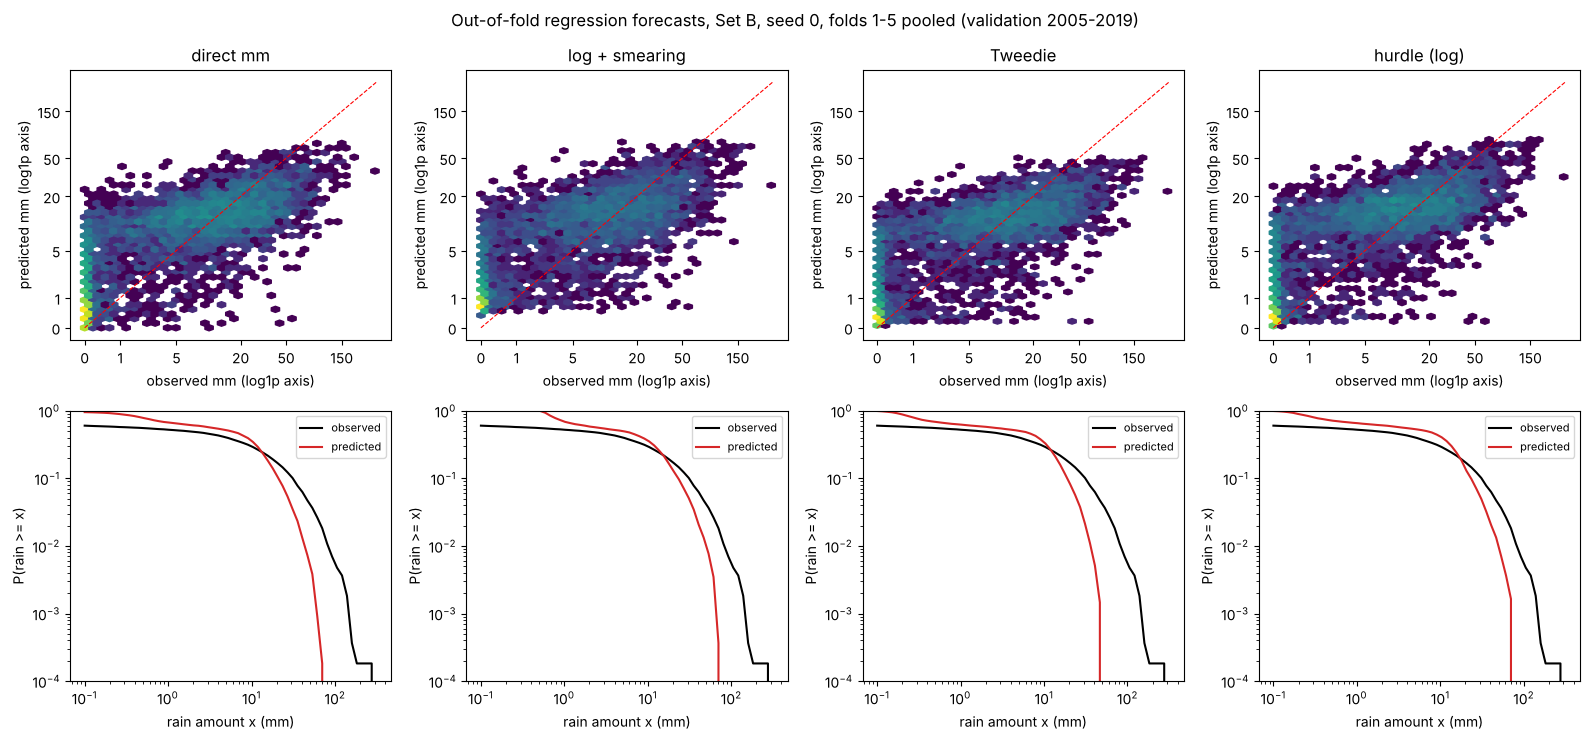

,direct mm,log + smearing,Tweedie,hurdle (log),observed
share >= 1 mm,0.670,0.689,0.622,0.654,0.523
share >= 20 mm,0.111,0.130,0.088,0.139,0.171
share >= 50 mm,0.005,0.011,0.000,0.010,0.042
max mm,70.890,73.230,50.540,77.390,288.100
std mm,9.807,10.982,8.609,11.151,18.487


In [8]:
SHOW = {"direct mm": "catboost__reg__B__seed0", "log + smearing": "catboost+log_smear__reg__B__seed0",
        "Tweedie": "catboost_tweedie__reg__B__seed0", "hurdle (log)": "hurdle_catboost_log__reg__B__seed0"}
oofs = {k: pd.read_parquet(E.OOF_DIR / f"{v}.parquet") for k, v in SHOW.items()}
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for i, (k, o) in enumerate(oofs.items()):
    ax = axes[0, i]
    hb = ax.hexbin(np.log1p(o["y_true"]), np.log1p(o["pred"]), gridsize=35, bins="log", cmap="viridis", mincnt=1)
    ax.plot([0, 5.7], [0, 5.7], "r--", lw=0.8)
    ticks = [0, 1, 5, 20, 50, 150]
    ax.set_xticks(np.log1p(ticks), ticks); ax.set_yticks(np.log1p(ticks), ticks)
    ax.set(title=f"{k}", xlabel="observed mm (log1p axis)", ylabel="predicted mm (log1p axis)")
    ax = axes[1, i]; x = np.logspace(-1, 2.5, 60)
    ax.plot(x, [(o["y_true"] >= v).mean() for v in x], "k-", label="observed")
    ax.plot(x, [(o["pred"] >= v).mean() for v in x], "tab:red", label="predicted")
    ax.set(xscale="log", yscale="log", ylim=(1e-4, 1), xlabel="rain amount x (mm)", ylabel="P(rain >= x)"); ax.legend(fontsize=8)
fig.suptitle("Out-of-fold regression forecasts, Set B, seed 0, folds 1-5 pooled (validation 2005-2019)")
fig.tight_layout(); save(fig, "04_regression_pred_vs_obs.png"); plt.show()
dist = pd.DataFrame({k: {"share >= 1 mm": (o["pred"] >= 1).mean(), "share >= 20 mm": (o["pred"] >= 20).mean(),
                         "share >= 50 mm": (o["pred"] >= 50).mean(), "max mm": o["pred"].max(), "std mm": o["pred"].std()}
                     for k, o in oofs.items()})
dist["observed"] = {"share >= 1 mm": (o["y_true"] >= 1).mean(), "share >= 20 mm": (o["y_true"] >= 20).mean(),
                    "share >= 50 mm": (o["y_true"] >= 50).mean(), "max mm": o["y_true"].max(), "std mm": o["y_true"].std()}
dist.round(3)

**Interpretation:**
- **All four formulations are under-dispersed:** prediction std 8.6–11.2 mm vs 18.5 observed; maximum forecast 50–77 mm vs 288 mm
  observed. Exceedance curves fall below the observed curve beyond ~10–15 mm: P(forecast ≥ 50 mm) is 0–1.1 % vs 4.2 % observed.
  This is not a bug — a forecast of the conditional mean (or median) averages over possible outcomes, so it cannot be as extreme as
  single realisations.
- **Too many small amounts:** 62–69 % of forecasts are ≥ 1 mm vs 52 % of observed days — dry days receive a few mm ("drizzle bias").
- Tweedie is the narrowest (never ≥ 50 mm, max 50 mm); log + smearing and hurdle reach furthest into the tail.
- In the density plots every approach shows the "flat" cloud: observed 0 → forecasts up to ~20 mm, observed 100 mm → forecasts
  20–60 mm.

**Decision:** for extremes, a probabilistic approach (e.g. P(rain ≥ 20/50 mm) as a classification target, or quantile regression) would
be more honest than a single amount — noted as a suggestion for later stages.

**Paper note:** *All regression formulations produced forecasts with roughly half the observed variability and rarely exceeded 50 mm
day⁻¹ (≤ 1.1 % of days versus 4.2 % observed), reflecting the inherent smoothing of conditional-mean forecasts.*

### What each regression approach assumes — and what we saw

| approach | assumption | what happened here |
|---|---|---|
| direct mm | symmetric errors | reasonable MSESS, MAE ≈ reference; smooth, under-dispersed |
| log + naive `expm1` | log-scale errors symmetric | best MAE but bias −4.7 mm/day → under-estimates totals by ~half (Jensen) |
| log + smearing | constant residual spread | bias −1.0, RMSE −1.4 mm vs naive; MAE +0.2 mm; remaining bias from seasonally varying spread |
| hurdle | occurrence ⟂ amount modelling | best MSESS (0.28), smallest bias, best heavy-rain recall (log amounts); MAE slightly worse |
| Tweedie (p = 1.5) | variance ∝ mean^1.5 | best consistent MAE (5/5 folds), MSESS = reference, bias −2.5; narrowest distribution |

**Failure mode common to all:** single-value forecasts of a heavy-tailed variable regress towards the centre; none forecasts 50-mm
days reliably. **Which one is "best" depends on the purpose:** totals/water balance → mean-type (hurdle-log, smearing); typical-day
accuracy → median-type (Tweedie, MAE loss).

# Part 3 — Prompt 4.6: complete comparison and sanity checks

### Step 11 — Master table: classification (baselines + all 10 classical models, Sets A and B)

**WHAT:** ranked by **PR-AUC** (pre-registered ranking metric), ties by BSS. The playbook's 10 classical models map to:
Logistic Regression = `logreg_none`, Ridge = `logreg_l2`, Lasso = `logreg_l1`, ElasticNet = `logreg_enet`, SGD = `sgd_logloss`,
Random Forest, XGBoost, LightGBM, CatBoost, MLP. Saved as `04_master_classification.csv`.

**WHY:** the single table for the paper; win counts make every claim paired.

**Look for:** whether the PR-AUC ranking agrees with the BSS ranking.

In [9]:
cv = pd.read_csv(E.RESULTS)
CLS10 = ["logreg_none", "logreg_l2", "logreg_l1", "logreg_enet", "sgd_logloss", "random_forest", "xgboost", "lightgbm",
         "catboost", "mlp"]
BASES = ["baseline:seasonal+persistence", "baseline:climatology", "baseline:persistence", "baseline:seasonal",
         "baseline:majority"]
m_cls = Rep.master_table(cv[cv.model.isin(CLS10 + BASES)], "cls", CLS_KEY + ["log_loss", "HSS"], ("PR_AUC", "BSS"),
                         {"seas+pers": SP, "logreg_l1": CLS_LIN})
m_cls.to_csv(TAB / "04_master_classification.csv")
m_cls

,metric,PR_AUC,BSS,BSS_vs_seas_pers,ROC_AUC,ROC_AUC_monsoon,CSI,ECE,log_loss,HSS,PR_AUC folds 1-3,PR_AUC folds 4-5,PR_AUC seed std,n_seeds,wins vs seas+pers,wins vs logreg_l1
model,feature_set,,,,,,,,,,,,,,,
logreg_l1,B,0.954 ± 0.015,0.253 ± 0.051,0.084 ± 0.009,0.955 ± 0.009,0.799 ± 0.031,0.817 ± 0.017,0.030 ± 0.006,0.270 ± 0.028,0.782 ± 0.014,0.944,0.970,0.000e+00,5,4/5,0/5
logreg_enet,B,0.954 ± 0.015,0.252 ± 0.049,0.083 ± 0.008,0.955 ± 0.009,0.794 ± 0.032,0.815 ± 0.021,0.034 ± 0.005,0.271 ± 0.027,0.780 ± 0.016,0.943,0.970,0.000e+00,5,4/5,0/5
logreg_l1,A,0.954 ± 0.016,0.247 ± 0.054,0.077 ± 0.012,0.954 ± 0.010,0.802 ± 0.035,0.821 ± 0.029,0.033 ± 0.008,0.273 ± 0.029,0.788 ± 0.028,0.943,0.970,0.000e+00,5,4/5,0/5
logreg_enet,A,0.953 ± 0.016,0.247 ± 0.053,0.077 ± 0.012,0.954 ± 0.010,0.801 ± 0.034,0.820 ± 0.029,0.032 ± 0.009,0.273 ± 0.029,0.786 ± 0.026,0.942,0.970,0.000e+00,5,4/5,1/5
logreg_l2,B,0.953 ± 0.015,0.249 ± 0.050,0.079 ± 0.014,0.954 ± 0.010,0.793 ± 0.032,0.816 ± 0.022,0.028 ± 0.007,0.271 ± 0.029,0.779 ± 0.019,0.942,0.969,0.000e+00,1,4/5,1/5
lightgbm,A,0.953 ± 0.019,0.258 ± 0.073,0.093 ± 0.040,0.955 ± 0.012,0.799 ± 0.038,0.816 ± 0.031,0.027 ± 0.006,0.267 ± 0.035,0.781 ± 0.034,0.940,0.972,5.000e-04,5,5/5,1/5
xgboost,A,0.953 ± 0.018,0.261 ± 0.070,0.095 ± 0.035,0.955 ± 0.012,0.797 ± 0.036,0.820 ± 0.029,0.027 ± 0.006,0.266 ± 0.034,0.787 ± 0.029,0.940,0.972,5.000e-04,5,5/5,1/5
logreg_l2,A,0.953 ± 0.016,0.241 ± 0.052,0.070 ± 0.015,0.953 ± 0.010,0.802 ± 0.037,0.821 ± 0.028,0.031 ± 0.008,0.274 ± 0.029,0.788 ± 0.026,0.941,0.970,0.000e+00,1,4/5,2/5
xgboost,B,0.953 ± 0.019,0.259 ± 0.062,0.092 ± 0.030,0.955 ± 0.012,0.797 ± 0.040,0.820 ± 0.030,0.028 ± 0.005,0.267 ± 0.034,0.785 ± 0.033,0.940,0.972,4.000e-04,5,5/5,1/5


**Interpretation:**
- **PR-AUC hardly separates the models:** the 16 best configurations lie between 0.946 and 0.954 — differences of 0.001–0.002, far
  below the fold std (0.015–0.02). It ranks `logreg_l1` first, whereas BSS ranks the boosters first (0.26 vs 0.25). PR-AUC is high for
  everybody because the season already ranks days well (climatology 0.92).
- On PR-AUC, the boosters, MLP and RF beat seasonal + persistence in 5/5 folds, the logistic models in 4/5.
- `logreg_l1` is beaten on PR-AUC in at most 1–2/5 folds by any model → no model ranks days consistently better than it.
- Calibration is good for all main models (ECE 0.027–0.034; RF 0.04).

**Decision (proposal, needs your approval):** PR-AUC was pre-registered as the ranking/Optuna metric (P1). On this data it is nearly
uninformative between strong models. I propose to keep it in the tables but use **BSS (equivalently Brier/log loss)** as the tuning
objective in Stage 6, because it measures probability quality and does separate the models.

**Paper note:** *Precision–recall AUC differed by less than 0.01 among the ten classical classifiers (0.944–0.954), whereas the Brier
skill score distinguished gradient boosting (0.26) from logistic regression (0.25) and from the MLP and random forest (0.24).*

### Step 12 — Master table: regression (baselines + all 10 classical models + the 4.5 variants)

**WHAT:** ranked by **MAE**, ties by MSESS. Playbook mapping: Linear Regression = `linreg`, Ridge, Lasso, ElasticNet, SGD =
`sgd_reg`, Random Forest, XGBoost, LightGBM, CatBoost, MLP (three losses), plus the variants. Saved as `04_master_regression.csv`.

**WHY:** as Step 11.

**Look for:** whether the MAE and MSESS rankings agree (they will not, Step 8).

In [10]:
REG10 = ["linreg", "ridge", "lasso", "elasticnet", "sgd_reg", "random_forest", "xgboost", "lightgbm", "catboost",
         "mlp_huber", "mlp_mae", "mlp_mse"]
reg_models = REG10 + BASES + [m for m in cv[cv.task == "reg"].model.unique() if any(k in m for k in ("+log", "hurdle", "tweedie"))]
m_reg = Rep.master_table(cv[cv.model.isin(reg_models)], "reg", REG_KEY + ["precision_ge20"], ("MAE", "MSESS"),
                         {"seas+pers": SP, "lasso": REG_LIN})
m_reg.to_csv(TAB / "04_master_regression.csv")
m_reg

,metric,MAE,MSESS,MSESS_vs_seas_pers,RMSE,bias,spearman_rho,MAE_wet,recall_ge20,recall_ge50,precision_ge20,MAE folds 1-3,MAE folds 4-5,MAE seed std,n_seeds,wins vs seas+pers,wins vs lasso
model,feature_set,,,,,,,,,,,,,,,,
mlp_mae,A,6.856 ± 1.990,0.152 ± 0.084,-0.103 ± 0.048,14.744 ± 4.371,-4.412 ± 2.059,0.823 ± 0.020,12.378 ± 2.771,0.248 ± 0.099,0.015 ± 0.029,0.686 ± 0.137,5.730,8.544,0.111,5,4/5,5/5
catboost_tweedie,A,6.901 ± 1.691,0.230 ± 0.085,-0.001 ± 0.033,14.034 ± 4.068,-2.501 ± 1.888,0.834 ± 0.020,11.811 ± 2.371,0.313 ± 0.144,0.013 ± 0.024,0.660 ± 0.158,5.950,8.327,0.007,5,5/5,5/5
catboost+log_naive,A,6.904 ± 2.063,0.130 ± 0.081,-0.133 ± 0.060,14.960 ± 4.522,-4.771 ± 2.182,0.837 ± 0.019,12.358 ± 2.943,0.191 ± 0.085,0.006 ± 0.011,0.739 ± 0.110,5.706,8.701,0.015,5,3/5,5/5
catboost_tweedie,B,6.905 ± 1.684,0.228 ± 0.087,-0.003 ± 0.033,14.048 ± 4.066,-2.486 ± 1.870,0.836 ± 0.020,11.823 ± 2.359,0.316 ± 0.151,0.012 ± 0.025,0.653 ± 0.171,5.959,8.324,0.014,5,5/5,5/5
mlp_mae,B,6.911 ± 2.008,0.150 ± 0.085,-0.105 ± 0.044,14.759 ± 4.371,-4.384 ± 2.352,0.830 ± 0.023,12.476 ± 2.803,0.242 ± 0.082,0.019 ± 0.037,0.660 ± 0.166,5.789,8.594,0.042,5,4/5,5/5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sgd_reg,A,7.456 ± 1.710,0.215 ± 0.076,-0.021 ± 0.045,14.211 ± 4.334,-1.582 ± 2.056,0.807 ± 0.031,12.063 ± 2.476,0.387 ± 0.153,0.001 ± 0.002,0.595 ± 0.140,6.508,8.879,0.043,5,0/5,1/5
baseline:persistence,-,7.904 ± 1.618,-0.037 ± 0.254,-0.326 ± 0.150,15.959 ± 3.763,-0.000 ± 0.000,0.824 ± 0.022,14.134 ± 1.821,0.509 ± 0.148,0.303 ± 0.147,0.509 ± 0.148,7.116,9.086,0.000,1,0/5,NaN
baseline:climatology,-,8.100 ± 2.464,0.000 ± 0.000,-0.315 ± 0.182,16.233 ± 5.654,-3.693 ± 3.202,0.747 ± 0.026,13.311 ± 3.935,0.000 ± 0.000,0.000 ± 0.000,nan ± nan,6.698,10.204,0.000,1,0/5,NaN


**Interpretation:** ranked by MAE, the top of the regression table is occupied by **median-type** forecasts (`mlp_mae` 6.86, CatBoost
Tweedie 6.90, log-naive boosters 6.90–6.94), all with MSESS **below** the reference (0.13–0.23) except Tweedie. Ranked by MSESS, the
hurdle-log models lead (0.276). The plain linear models (linreg, Ridge, Lasso, ElasticNet, SGD) are at the bottom (MAE 7.29–7.46), above
only the single-source baselines. Of 66 regression model configurations, only **CatBoost Tweedie (A and B)** and **hurdle CatBoost direct (B)**
beat seasonal + persistence on MAE in 5/5 folds.

**Decision:** in the paper, regression results are presented as a **two-metric view** (MAE and MSESS, with bias), not a single ranking.

**Paper note:** *The ranking of regression models depended on the error metric: models minimising absolute error ranked first by MAE
but underestimated mean rainfall, whereas hurdle and bias-corrected log models ranked first by MSE skill.*

### Step 13 — Red-flag checklist (a, b): too-good scores and the test set

**WHAT:** (a) every fold of every configuration against the approved triggers (BSS > 0.45, monsoon ROC-AUC > 0.90,
MSESS > 0.60); (b) an audit: latest target date in all stored OOF predictions, folds present in `cv_results.csv`, and every file
in `src/`, `tests/`, `notebooks/` that contains `confirm_final=True`.

**WHY:** rule 11 and rule 4, checked by code rather than by memory.

**Look for:** 0 trigger hits; latest target 2019-12-31; `confirm_final=True` only in the unit test that verifies the lock.

In [11]:
trig = {"BSS": 0.45, "ROC_AUC_monsoon": 0.90, "MSESS": 0.60}
hits = cv[cv.metric.isin(trig) & (cv.value > cv.metric.map(trig))]
print(f"configurations: {cv.groupby(E.KEYS).ngroups} | fold-level trigger hits: {len(hits)} | "
      f"max: {cv[cv.metric.isin(trig)].groupby('metric')['value'].max().round(3).to_dict()}")
pd.Series(Rep.test_set_audit(), dtype=object).to_frame("audit")

configurations: 346 | fold-level trigger hits: 0 | max: {'BSS': 0.339, 'MSESS': 0.444, 'ROC_AUC_monsoon': 0.874}


,audit
OOF files checked,336
latest target date in any OOF file,2019-12-31
folds present in cv_results,"[1, 2, 3, 4, 5]"
"files calling test_index(..., confirm_final=True)",[tests/test_splits.py]


**Interpretation:**
- **(a) Too-good scores:** 0 fold-level hits in 346 configurations; maxima BSS 0.339, MSESS 0.444, monsoon ROC-AUC 0.874 — all below the
  approved triggers.
- **(b) Test set:** 336 OOF files checked — latest target date **2019-12-31**; `cv_results.csv` contains folds 1–5 only; the only file that
  calls `test_index(..., confirm_final=True)` is `tests/test_splits.py`, the unit test that verifies the lock. *Honest note:* the first
  version of this audit searched for the plain text `confirm_final=True` and flagged `src/splits.py` and `src/reporting.py` — false
  positives (an error message and the audit's own string). The check was tightened to match only actual calls and re-run (rule 12: show
  the problem, explain, fix).

**Decision:** rules 4 and 11 satisfied for Stage 4.

**Paper note:** *No model met any pre-specified implausibility criterion, and an automated audit confirmed that no prediction or score
involved the 2020–2025 test period.*

### Step 14 — Red flag (c): does a single feature dominate the boosters?

**WHAT:** refit CatBoost, LightGBM and XGBoost (seed 0, Set B, fold-5 training rows, number of trees = median from CV) for both tasks
and compute each library's **gain-based importance** share; aggregate shares by **physical variable group** (e.g. all rain lags,
sums and spell counters → "rain"); then **permutation importance** of CatBoost on the fold-5 validation block (drop in Brier score
/ increase in MAE when one feature is shuffled; 3 repeats).

**WHY:** if one feature carried > ~40 % of the importance, the model could be a disguised persistence rule — or a leak. Gain
importance splits credit among correlated features, so grouped shares are more meaningful; permutation importance measures the
effect on the actual score (diagnostic only: nothing is tuned on it).

**Alternatives considered:** SHAP values — richer, planned for the interpretation stage.

**Look for:** the top feature's share, the top group's share, and agreement between gain and permutation rankings.

top feature  share top-5 share      top group group share
cls catboost  rain_log1p  0.201       0.309  rain & spells       0.311
    lightgbm  rain_log1p  0.579       0.695  rain & spells       0.631
    xgboost    wet_today  0.359       0.697  rain & spells       0.665
reg catboost  rain_log1p  0.261       0.431  rain & spells       0.364
    lightgbm  rain_log1p   0.43       0.537  rain & spells       0.507
    xgboost    wet_today  0.216        0.35  rain & spells       0.373

cls                       reg                 
              catboost lightgbm xgboost catboost lightgbm xgboost
rain & spells    0.311    0.631   0.665    0.364    0.507   0.373
T2M_MIN          0.057    0.081   0.075    0.040    0.050   0.094
WS2M             0.050    0.021   0.020    0.126    0.092   0.063
RH2M             0.095    0.042   0.029    0.073    0.058   0.065
WS10M            0.057    0.024   0.021    0.099    0.060   0.062
PS               0.077    0.044   0.031    0.049    0.038   0.051
T2MDEW           0.074    0.027   0.035    0.057    0.032   0.061
QV2M             0.063    0.031   0.036    0.049    0.032   0.059
season           0.071    0.034   0.027    0.049    0.035   0.043
T2M              0.052    0.024   0.031    0.039    0.041   0.062

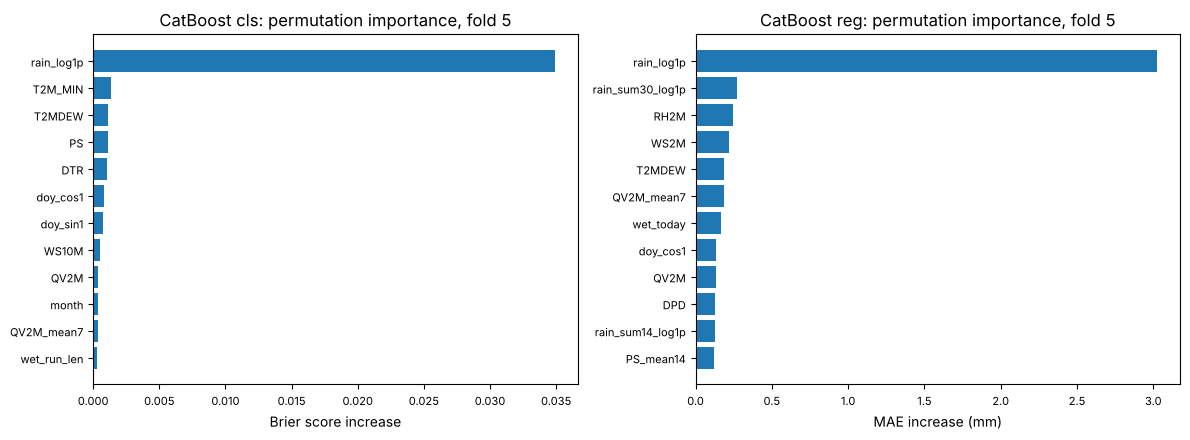

In [12]:
import re
def group(f):
    if f.startswith(("rain", "wet_", "days_since")): return "rain & spells"
    if f.startswith(("doy_", "month")): return "season"
    return re.sub(r"(_lag\d+|_mean\d+|_chg1)$", "", f)

tr, va = FOLDS[4]
imp, fitted = {}, {}
for task in ("cls", "reg"):
    y = Y[E.TARGET[task]]
    for name in ("catboost", "lightgbm", "xgboost"):
        est = Mo.trees(task)[name](0, y[tr])
        n = int(cv.query("model == @name and task == @task and feature_set == 'B' and metric == 'n_trees'")["value"].median())
        E.set_trees(est, n); est.fit(X.loc[tr], y[tr]); fitted[task, name] = est
        raw = (est.get_feature_importance() if name == "catboost" else
               est.booster_.feature_importance(importance_type="gain") if name == "lightgbm" else
               est.get_booster().get_score(importance_type="gain"))
        s = pd.Series(raw, index=X.columns) if name != "xgboost" else pd.Series(raw).reindex(X.columns).fillna(0)
        imp[task, name] = s / s.sum()
imp = pd.DataFrame(imp)
top = pd.DataFrame({k: {"top feature": imp[k].idxmax(), "share": imp[k].max(), "top-5 share": imp[k].nlargest(5).sum(),
                        "top group": imp[k].groupby(group).sum().idxmax(), "group share": imp[k].groupby(group).sum().max()}
                    for k in imp}).T
display(top.round(3))
grp = imp.groupby(group).sum()
display(grp.loc[grp.mean(axis=1).sort_values(ascending=False).index].round(3).head(10))
imp.round(4).to_csv(TAB / "04_booster_gain_importance_fold5.csv")

perm = {}
for task, scoring in (("cls", "neg_brier_score"), ("reg", "neg_mean_absolute_error")):
    pi = permutation_importance(fitted[task, "catboost"], X.loc[va], Y.loc[va, E.TARGET[task]], scoring=scoring,
                                n_repeats=3, random_state=0, n_jobs=1)
    perm[task] = pd.Series(pi.importances_mean, index=X.columns)
perm = pd.DataFrame(perm)
perm.round(5).to_csv(TAB / "04_catboost_permutation_importance_fold5.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, task, unit in ((axes[0], "cls", "Brier score increase"), (axes[1], "reg", "MAE increase (mm)")):
    t = perm[task].nlargest(12)[::-1]; ax.barh(t.index, t); ax.set(title=f"CatBoost {task}: permutation importance, fold 5", xlabel=unit)
    ax.tick_params(labelsize=8)
fig.tight_layout(); save(fig, "04_catboost_permutation_importance.png"); plt.show()

**Interpretation — yes, one feature dominates, and it is today's rain:**
- Gain importance: `rain_log1p` takes **58 %** of LightGBM's classification gain (43 % for regression); XGBoost puts 36 % on `wet_today`;
  CatBoost spreads credit more evenly (top feature 20–26 %, because its symmetric trees reuse features across a whole level). Grouped,
  **"rain & spells" accounts for 31–67 %** of the gain.
- **Permutation importance (CatBoost, fold 5) is even clearer:** shuffling `rain_log1p` raises the Brier score by **0.035** — about
  **25 times** more than the next feature (`T2M_MIN`, +0.0013) — and raises MAE by **3.0 mm** vs ≤ 0.27 mm for any other feature
  (`rain_sum30_log1p`, RH2M, WS2M, dew point…).
- **Is it a leak?** No: `rain_log1p` is rain on day t, verified by the Stage-2 truncation and target-shift tests, and its correlation
  with tomorrow's rain (ρ = 0.81) was measured in Stage 1. **What it means:** the classical models are essentially *smart persistence*
  — they adjust "rain tomorrow ≈ rain today" with moisture, temperature, pressure and season. Their skill therefore depends on how
  persistent the target series is.

**Decision:** report this openly; it strengthens the case for the IMERG check (is persistence equally strong in satellite rain?).

**Paper note:** *Same-day rainfall dominated the importance of all boosted models (permutation: 25 times the Brier-score impact of the
next predictor), indicating that the learned models act largely as moisture- and season-adjusted persistence forecasts.*

### Step 15 — Red flag (d): which models change a lot across seeds?

**WHAT:** the seed std of the 5-fold mean headline metric (BSS, MAE) for every multi-seed configuration, compared with the
typical paired gain over the reference.

**WHY:** a model whose ranking depends on the seed cannot be called "better"; and if the seed std is comparable to the gains
we report, we need more seeds or must say the difference is not resolved.

**Look for:** configurations with seed std > 0.01 BSS or > 0.05 mm MAE.

In [13]:
stab = Rep.seed_stability(cv[cv.model.isin(CLS10 + reg_models)], ["BSS", "MAE"])
stab["flag"] = np.where(stab.metric == "BSS", stab.seed_std > 0.01, stab.seed_std > 0.05)
stab.to_csv(TAB / "04_seed_stability.csv", index=False)
print("flagged:", stab["flag"].sum(), "of", len(stab))
stab.head(15).round(4)

flagged: 8 of 62


,model,task,feature_set,metric,mean,seed_std,n_seeds,flag
68,mlp_mae,reg,A,MAE,6.856,0.111,5,True
70,mlp_mse,reg,A,MAE,7.111,0.108,5,True
71,mlp_mse,reg,B,MAE,7.090,0.077,5,True
67,mlp_huber,reg,B,MAE,6.992,0.065,5,True
85,sgd_reg,reg,B,MAE,7.447,0.062,5,True
66,mlp_huber,reg,A,MAE,6.988,0.056,5,True
84,sgd_reg,reg,A,MAE,7.456,0.043,5,False
69,mlp_mae,reg,B,MAE,6.911,0.042,5,False
95,xgboost_tweedie,reg,B,MAE,6.953,0.033,5,False
52,lightgbm_tweedie,reg,A,MAE,6.993,0.032,5,False


**Interpretation:** 8 of 62 multi-seed configurations exceed the stability thresholds: **all six MLP regression configurations**
(seed std 0.056–0.111 mm MAE), `sgd_reg` (B, 0.062 mm) and `sgd_logloss` (B, 0.032 BSS). The boosters and RF are stable (≤ 0.033 mm,
≤ 0.003 BSS). For the MLPs the seed std is comparable to their gains over the reference (≈ 0.1–0.2 mm), so **their regression ranking is
not resolved by 5 seeds**.

**Decision:** treat MLP/SGD regression differences as unresolved; if an MLP becomes a finalist, use ≥ 10 seeds.

**Paper note:** *Seed-to-seed variability was negligible for tree ensembles but comparable to the between-model differences for the
MLP and SGD regressors, whose rankings were therefore considered unresolved.*

### Step 16 — Summary figure

**WHAT:** paired gain over seasonal + persistence per model (mean over folds; error bar = min/max over folds): BSS (classification)
and MAE reduction (regression), Set B.

**WHY:** one figure for the results section that shows both the size and the consistency of every model's gain.

**Look for:** bars whose whole min–max range is above 0 (consistent gain).

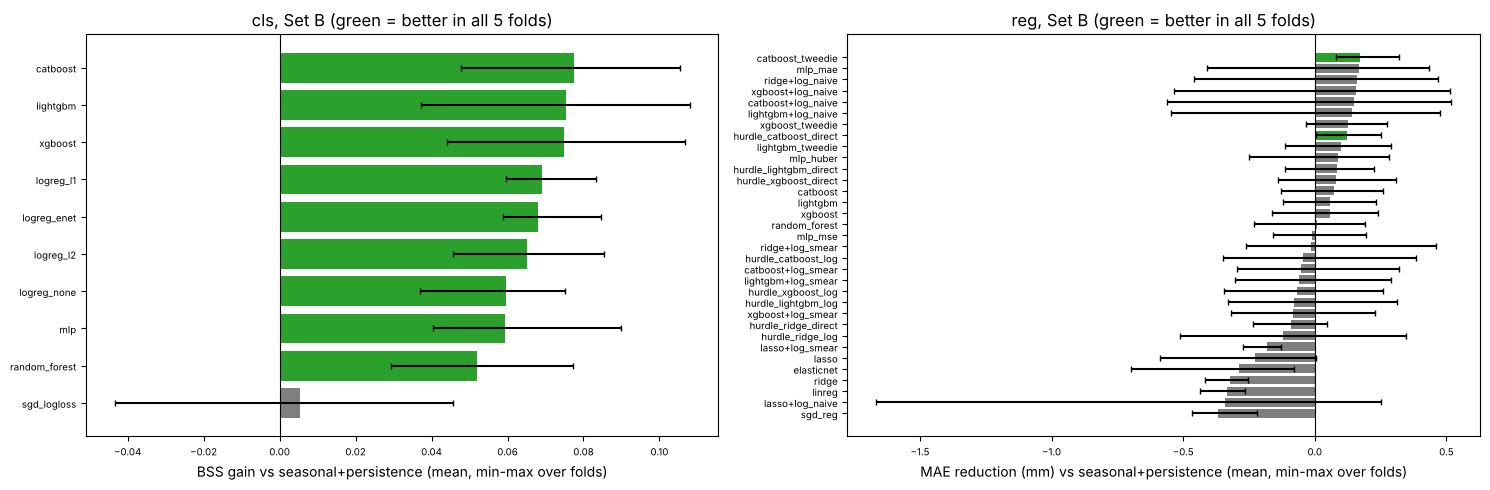

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, task, metric, models, sign in ((axes[0], "cls", "BSS", CLS10, 1), (axes[1], "reg", "MAE", reg_models, -1)):
    ft = Rep.fold_table(cv, task, metric)
    ref = ft.loc[SP]
    rows = [(m, sign * (ft.loc[(m, "B")] - ref)) for m in models if (m, "B") in ft.index and not m.startswith("baseline")]
    rows.sort(key=lambda r: r[1].mean())
    names = [m for m, _ in rows]; d = [r for _, r in rows]
    mean = np.array([x.mean() for x in d]); lo = mean - np.array([x.min() for x in d]); hi = np.array([x.max() for x in d]) - mean
    ax.barh(names, mean, xerr=[lo, hi], color=np.where(np.array([x.min() for x in d]) > 0, "tab:green", "tab:grey"), capsize=2)
    ax.axvline(0, color="k", lw=0.8); ax.tick_params(labelsize=7)
    ax.set(xlabel=f"{'BSS gain' if task == 'cls' else 'MAE reduction (mm)'} vs seasonal+persistence (mean, min-max over folds)",
           title=f"{task}, Set B (green = better in all 5 folds)")
fig.tight_layout(); save(fig, "04_paired_gain_vs_reference.png"); plt.show()

**Interpretation:** **classification:** every model except SGD improves on seasonal + persistence in all 5 folds (green), by +0.05 to +0.08 BSS
on average; the boosters lead, then the regularised logistic models, then MLP and RF. **Regression:** the picture is the opposite — only
**CatBoost Tweedie** and **hurdle CatBoost direct** are green; most error bars straddle 0, and all linear models on mm are worse than the
reference in most folds.

**Decision:** figure for the results section (`04_paired_gain_vs_reference.png`).

**Paper note:** *Gains over the seasonal-persistence reference were consistent across all validation periods for nine of ten classifiers,
but for only two of the regression configurations.*

## SKEPTICAL-REVIEWER: how a critical reviewer would attack Stage 4

| # | Criticism | Our answer / status |
|---|---|---|
| 1 | *"Your 'best' regression model depends on the metric you chose."* | **True.** MAE rewards median forecasts (bias up to −4.8 mm/day, i.e. totals under-estimated by ~half); MSE rewards mean forecasts. We report MAE, MSESS and bias together and state which purpose each candidate serves. |
| 2 | *"Your ML models are just persistence."* | **Largely true** (permutation importance: today's rain ≫ everything else). The added value is +0.05–0.10 BSS over seasonal + persistence, consistent across folds — real but modest. |
| 3 | *"Reanalysis rain is smooth; persistence is inflated."* | Plausible and untested. IMERG robustness (Stage 6) must re-measure both persistence and model gains. |
| 4 | *"Post-2016 gains are a data artefact."* | Boosters beat logistic regression only in folds 4–5 (part 1). Unresolved until the IMERG experiment and a training-window ablation. |
| 5 | *"You compared ~86 model configurations (20 classification, 66 regression) and picked the best on the same folds (winner's curse)."* | Valid. Differences among the top models (≤ 0.01 BSS, ≤ 0.1 mm MAE) are within selection noise. Mitigation: pre-registered metrics, paired fold wins, a small finalist list, and a single test-set evaluation. |
| 6 | *"PR-AUC was your ranking metric but cannot separate models."* | Confirmed (spread 0.008 across 10 classifiers). Proposal: BSS / log loss as tuning objective (needs approval). |
| 7 | *"Defaults are not a fair comparison."* | True for SGD (unconverged), Lasso on the log scale (α set for mm) and the MLP. Stage-6 tuning addresses this; until then conclusions about *families* are provisional. |
| 8 | *"Heavy rain is what matters for flooding, and you cannot forecast it."* | Correct: recall ≥ 50 mm ≤ 0.12 for every ML formulation vs 0.30 for persistence. Single-value regression is the wrong tool for extremes; suggest probabilistic exceedance targets (P(≥ 20/50 mm)) as future work. |
| 9 | *"Hurdle uses classifier probabilities computed elsewhere."* | They are the saved OOF predictions from the identical fold/slice procedure (same seed, same set), never fitted on validation data. |
| 10 | *"Your test-set audit flagged files."* | First version produced false positives (plain-text search); fixed to match real calls; only the lock's unit test unlocks the test set. Documented. |

## Stage 4 summary (parts 1 and 2)

| question | answer |
|---|---|
| Best classifiers | CatBoost / LightGBM / XGBoost BSS ≈ 0.26; logreg_l1 0.25; MLP 0.24; RF 0.24 — all (except SGD) beat seasonal + persistence in 5/5 folds |
| Non-linear advantage for occurrence | small (+0.01 BSS), only post-2016 |
| Best regression | metric-dependent: **CatBoost Tweedie** (MAE 6.90, 5/5 folds vs reference) · **hurdle CatBoost-log** (MSESS 0.28, bias −0.5, best heavy-rain recall) |
| Jensen bias | naive expm1 −4.6 to −5.8 mm/day; smearing (S ≈ 1.6) → −1.0 to −2.1 |
| MLP | needs scaling + early stopping (over-fits after ~20 epochs); seed-sensitive; not better than logistic regression |
| Red flags | none triggered; test set untouched (audited); persistence dominates importance; MLP/SGD unstable across seeds |
| Pending your decision | (1) tuning objective for Stage 6 (BSS/log loss instead of PR-AUC?); (2) regression candidates (Tweedie and/or hurdle-log) |

Outputs: `notebooks/04_classical_ml_part2.ipynb`, `src/mlp.py`, `src/reg_variants.py`, `src/reporting.py`, `tests/test_mlp.py`,
`reports/tables/04_master_classification.csv`, `04_master_regression.csv`, `04_regression_variants.csv`, `04_jensen_log_backtransform.csv`,
`04_seed_stability.csv`, importance tables; figures `04_mlp_learning_curves.png`, `04_regression_pred_vs_obs.png`,
`04_catboost_permutation_importance.png`, `04_paired_gain_vs_reference.png`; 336 OOF files.